In [4]:
import h5py
import matplotlib.pyplot as plt
import numpy as np


In [33]:

def hotpixel_map(image_dark):
    std = image_dark.std()
    mean = image_dark.mean()
    mask = image_dark >= mean + 2 * std
    return mask

def deadpixel_map(image_flat):
    std = image_flat.std()
    mean = image_flat.mean()
    mask = image_flat <= mean - 2 * std
    return mask

In [ ]:
dset_path_darks = "239.1/instrument/andor_image/data"
dset_path_flats = "240.1/instrument/andor_image/data"

datapaths = {"darks" : "/asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/raw/075_calibration/scan_00239/scan_00239.h5",
             "flats" : "/asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/raw/075_calibration/scan_00240/scan_00240.h5"}

with h5py.File(datapaths["darks"], "r") as f:
    darks_arr = f[dset_path_darks][:]

with h5py.File(datapaths["flats"], "r") as f:
    flats_arr = f[dset_path_flats][:]

dead_mask = [] 
hot_mask = []
broken_mask = []
for i in range(flats_arr.shape[0]):
    dead_mask.append(deadpixel_map(flats_arr[i]))
    hot_mask.append(hotpixel_map(darks_arr[i]))


sum_dead_map = np.sum(np.asarray(dead_mask),axis=0)
sum_hot_map = np.sum(np.asarray(hot_mask),axis=0)


KeyError: 'Unable to synchronously open object (component not found)'

In [28]:
print("Flats:", flats_arr.shape, flats_arr.dtype)
print("Flats min/max:", np.nanmin(flats_arr), np.nanmax(flats_arr))

dead = np.asarray(dead_mask)
hot = np.asarray(hot_mask)

print("Dead masks:", dead.shape, dead.dtype,
      "nonzero:", np.count_nonzero(dead))
print("Hot masks:", hot.shape, hot.dtype,
      "nonzero:", np.count_nonzero(hot))

print("Dead sum min/max:", sum_dead_map.min(), sum_dead_map.max())
print("Hot sum min/max:", sum_hot_map.min(), sum_hot_map.max())

Flats: (6, 1080, 1280) int16
Flats min/max: 0 0
Dead masks: (6, 1080, 1280) bool nonzero: 8294400
Hot masks: (6, 1080, 1280) bool nonzero: 8294400
Dead sum min/max: 6 6
Hot sum min/max: 6 6


In [30]:
with h5py.File(datapaths["flats"], "r") as f:
    ds = f[dset_path_flats]
    frame = ds[0]

    print("File:", f.filename)
    print("Dataset:", ds.name)
    print("Shape/dtype:", ds.shape, ds.dtype)
    print("First frame min/max:", frame.min(), frame.max())
    print("Attributes:", dict(ds.attrs))

File: /asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/raw/075_calibration/scan_00240/scan_00240.h5
Dataset: /240.1/instrument/andor_image/data
Shape/dtype: (6, 1080, 1280) int16
First frame min/max: 0 0
Attributes: {'interpretation': 'image'}


In [31]:
with h5py.File(datapaths["flats"], "r") as f:
    ds = f[dset_path_flats]
    print("Virtual dataset:", ds.is_virtual)
    print("Fill value:", ds.fillvalue)

    if ds.is_virtual:
        for source in ds.virtual_sources():
            print("Source:", source.file_name, source.dset_name)

Virtual dataset: True
Fill value: 0
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000001.nx /entry/instrument/detector/data
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000002.nx /entry/instrument/detector/data
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000003.nx /entry/instrument/detector/data
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000004.nx /entry/instrument/detector/data
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000005.nx /entry/instrument/detector/data
Source: /gpfs/current/raw/075_calibration/zyla//scan_240__000006.nx /entry/instrument/detector/data


In [34]:

source = "/asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/raw/075_calibration/zyla/scan_240__000001.nx"

with h5py.File(source, "r") as f:
    frame = f["/entry/instrument/detector/data"][0]
    print(frame.min(), frame.max())

120 898


In [9]:
from pathlib import Path
import h5py
import numpy as np

data_dir = Path(
    "/asap3/spec.instruments/gpfs/demonstrator/2026/data/"
    "11024317/raw/075_calibration/zyla"
)

def load_scan(scan_number):
    files = sorted(
        path for path in data_dir.glob(f"scan_{scan_number}_*")
        if path.is_file() and path.suffix in {".nx", ".h5"}
    )
    frames = []
    for path in files:
        with h5py.File(path, "r") as f:
            data = f["/entry/instrument/detector/data"][:]
        # Normalize a single image to (1, height, width).
        if data.ndim == 2:
            data = data[np.newaxis, ...]
        if data.ndim != 3:
            raise ValueError(f"Unexpected shape {data.shape} in {path.name}")
        frames.append(data)
    return np.concatenate(frames, axis=0)


darks_arr = load_scan(239)
flats_arr = load_scan(240)

print("Darks:", darks_arr.shape, darks_arr.dtype,
      "min/max:", darks_arr.min(), darks_arr.max())
print("Flats:", flats_arr.shape, flats_arr.dtype,
      "min/max:", flats_arr.min(), flats_arr.max())

Darks: (6, 1080, 1280) uint16 min/max: 90 124
Flats: (6, 1080, 1280) uint16 min/max: 115 1150


In [46]:
dead_mask = [] 
hot_mask = []
broken_mask = []
for i in range(flats_arr.shape[0]):
    dead_mask.append(deadpixel_map(flats_arr[i]))
    hot_mask.append(hotpixel_map(darks_arr[i]))


sum_dead_map = np.sum(np.asarray(dead_mask),axis=0)
sum_hot_map = np.sum(np.asarray(hot_mask),axis=0)

In [45]:
print(flats_arr.mean())
print(flats_arr.std())

147.20004906925155
4.022263049701622


0.09782986111111111 6


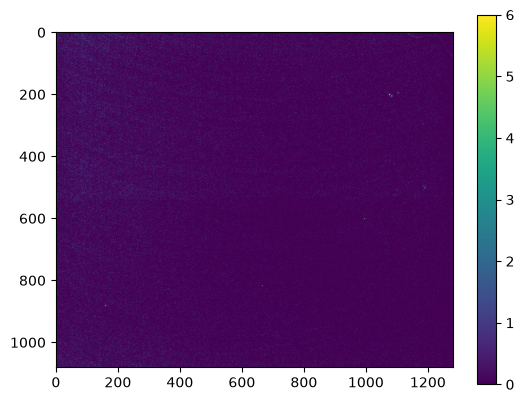

In [47]:
plt.imshow(sum_dead_map)
plt.colorbar()
print(sum_dead_map.mean(), sum_dead_map.max())

0.20052083333333334 6


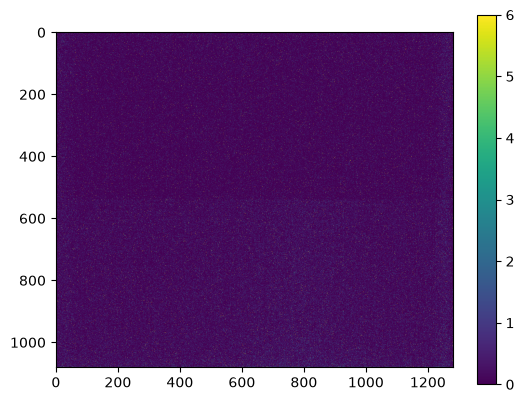

In [48]:
plt.imshow(sum_hot_map)
plt.colorbar()
print(sum_hot_map.mean(), sum_hot_map.max())

0.002663483796296296 1


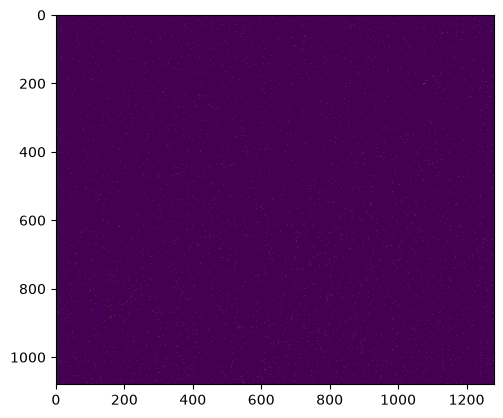

In [49]:

dead_map = (sum_hot_map == 6).astype(np.uint8) | (sum_dead_map == 6).astype(np.uint8)
plt.imshow(dead_map)
print(dead_map.mean(), dead_map.max())

In [52]:
save_path = "/asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/processed/calibration/0001_defectmap.h5"

with h5py.File(save_path, "w") as f:
    f.create_dataset("defect_map", data=dead_map)

print(f"Defect map saved to: {save_path}")

Defect map saved to: /asap3/spec.instruments/gpfs/demonstrator/2026/data/11024317/processed/calibration/0001_defectmap.h5


In [31]:
#TODO write robust detection of dead pixels from a darkfield and a flatfield image. 

# derivation kernel 

In [32]:
#TODO create a Kernel that goes through an image and flags pixels that are birghter or less bright than 2x of the standard derivation 